## Experiment: Deep Learning on U-Shape Dataset with Zero Weight Initialization

This notebook demonstrates the training behavior of a simple feedforward neural network when all weights are initialized to exactly `0.0`.

### Key Concepts Explored:
* **Symmetry Breaking Problem**: When all weights in a layer are initialized to the exact same value (such as 0), every hidden unit (neuron) in that layer will compute the exact same output during the forward pass and receive the exact same gradients during backpropagation. This prevents the model from learning distinct features, effectively collapsing the multi-neuron layer into a single-neuron representation.
* **Linear Decision Boundary**: As observed in the decision regions plot, the resulting boundary remains a simple linear classifier because the hidden units cannot learn unique features to map the non-linear u-shape distribution.

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [16]:
from sklearn.datasets import make_moons
# Generate a synthetic u-shape (half-moon) dataset
X, y = make_moons(n_samples=100, noise=0.1, random_state=42)
df = pd.DataFrame(X, columns=['X1', 'X2'])
df['Class'] = y

In [17]:
df.head()

,X1,X2,Class
0,1.582023,-0.445815,1
1,0.066045,0.439207,1
2,0.736631,-0.398963,1
3,-1.056928,0.242456,0
4,-0.802162,0.202718,0


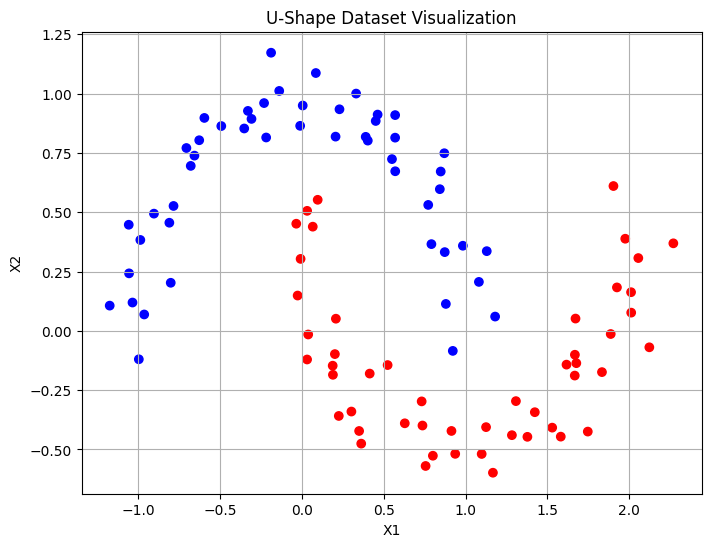

In [18]:
plt.figure(figsize=(8, 6))
plt.scatter(df.iloc[:, 0], df.iloc[:, 1], c=df.iloc[:, 2] if df.shape[1] > 2 else None, cmap='bwr')
plt.title('U-Shape Dataset Visualization')
plt.xlabel('X1')
plt.ylabel('X2')
plt.grid(True)
plt.show()

In [19]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [20]:
model = Sequential()
model.add(Dense(10, activation='sigmoid', input_dim=2))
model.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [21]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 10)             │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 41 (164.00 B)

 Trainable params: 41 (164.00 B)

 Non-trainable params: 0 (0.00 B)

In [22]:
model.get_weights()

[array([[ 0.34710342, -0.6996417 , -0.527223  , -0.39016518,  0.27354228,
          0.51031154, -0.45909804,  0.26328582, -0.17997211, -0.33608064],
        [ 0.6858937 ,  0.14234877, -0.49373752,  0.04131085,  0.2996189 ,
          0.27750427, -0.01669484,  0.35924405,  0.66049284, -0.48322457]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[-0.38912985],
        [-0.32322222],
        [ 0.03635126],
        [ 0.50719637],
        [ 0.44150954],
        [ 0.42843372],
        [ 0.41468066],
        [ 0.2400499 ],
        [-0.13341409],
        [-0.7152027 ]], dtype=float32),
 array([0.], dtype=float32)]

In [23]:
inital_weights = model.get_weights()

In [24]:
weights = model.get_weights()
initial_weights = []
for w in weights:
    initial_weights.append(np.zeros(w.shape) * 0.5)

In [25]:
model.set_weights(initial_weights)

In [26]:
model.get_weights()

[array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]], dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.]], dtype=float32),
 array([0.], dtype=float32)]

In [27]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [28]:
history = model.fit(X,y,epochs=100,validation_split=0.2)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 119ms/step - accuracy: 0.5250 - loss: 0.6934 - val_accuracy: 0.4000 - val_loss: 0.6942
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.5250 - loss: 0.6929 - val_accuracy: 0.4000 - val_loss: 0.6943
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.5250 - loss: 0.6928 - val_accuracy: 0.4000 - val_loss: 0.6948
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.5250 - loss: 0.6927 - val_accuracy: 0.4000 - val_loss: 0.6953
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.5250 - loss: 0.6926 - val_accuracy: 0.4000 - val_loss: 0.6959
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.5250 - loss: 0.6924 - val_accuracy: 0.4000 - val_loss: 0.6964
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.5250 - loss: 0.6924 - val_accuracy: 0.4000 - val_loss: 0.6971
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.5250 - loss: 0.6923 - val_accuracy: 0.4000 - val_loss

In [30]:
model.get_weights()

[array([[-0.4306745 , -0.4306745 , -0.4306745 , -0.4306745 , -0.4306745 ,
         -0.4306745 , -0.4306745 , -0.4306745 , -0.4306745 , -0.4306745 ],
        [ 0.43604222,  0.43604222,  0.43604222,  0.43604222,  0.43604222,
          0.43604222,  0.43604222,  0.43604222,  0.43604222,  0.43604222]],
       dtype=float32),
 array([-0.07825659, -0.07825659, -0.07825659, -0.07825659, -0.07825659,
        -0.07825659, -0.07825659, -0.07825659, -0.07825659, -0.07825659],
       dtype=float32),
 array([[-0.08457203],
        [-0.08457203],
        [-0.08457203],
        [-0.08457203],
        [-0.08457203],
        [-0.08457203],
        [-0.08457203],
        [-0.08457203],
        [-0.08457203],
        [-0.08457203]], dtype=float32),
 array([0.05087186], dtype=float32)]

9600/9600 ━━━━━━━━━━━━━━━━━━━━ 13s 1ms/step


<Axes: >

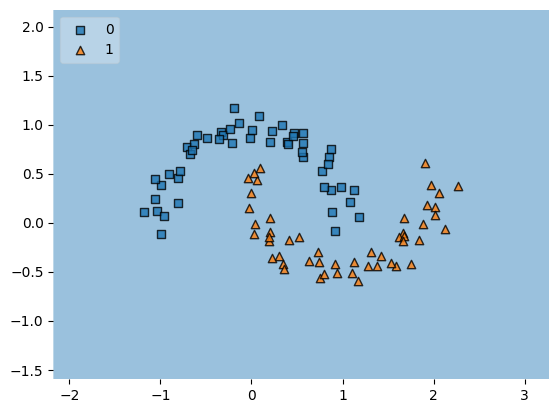

In [31]:
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(X,y.astype('int'), clf=model, legend=2)